# Week 2 - Wednesday: Naive Bayes and Pipelines

**Datasets:** Wine and Breast Cancer (built in), Titanic (seaborn, needs internet)

**Goal:** learn Naive Bayes, and build a single Pipeline (preprocessing + model) where the classifier can be swapped by changing one line.

**Done when:** one pipeline object goes from raw Titanic data to a prediction, and I can swap the model by changing one line.

---
### Quick theory
**Naive Bayes**
- Uses **Bayes' theorem** to find the probability of each class given the features, then predicts the most probable class:

  `P(class | features)  is proportional to  P(class) x P(feature 1 | class) x P(feature 2 | class) x ...`
- **"Naive"** = it assumes all features are **independent** of each other given the class. This is rarely true, but the model still works well.
- **GaussianNB** assumes each continuous feature follows a normal (bell-curve) distribution within each class.
- Very fast and works well on small data. Weakness: strongly correlated features break the independence assumption.

**Pipelines**
- `Pipeline` chains preprocessing and a model into one object. `fit` runs all steps in order, `predict` takes raw data and returns predictions.
- `ColumnTransformer` applies different preprocessing to different columns (numeric vs categorical).
- `make_pipeline` is a shortcut that names the steps automatically.
- **Why it prevents leakage:** inside cross-validation, the pipeline refits the imputer, scaler and encoder on each **training fold only**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")

## Step 1: GaussianNB vs Decision Tree vs kNN on Wine and Breast Cancer
Naive Bayes and trees do not need scaling, but kNN does, so kNN gets a small pipeline with `StandardScaler`.

In [2]:
datasets = {
    "Wine": load_wine(as_frame=True),
    "Breast Cancer": load_breast_cancer(as_frame=True),
}

models = {
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "kNN (scaled)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

rows = []
for ds_name, data in datasets.items():
    X, y = data.data, data.target
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=42
    )
    for model_name, model in models.items():
        model.fit(X_train, y_train)
        test_acc = model.score(X_test, y_test)
        cv_acc = cross_val_score(model, X, y, cv=5).mean()
        rows.append([ds_name, model_name, round(test_acc, 3), round(cv_acc, 3)])

step1 = pd.DataFrame(rows, columns=["Dataset", "Model", "Test acc", "5-fold CV mean"])
step1

,Dataset,Model,Test acc,5-fold CV mean
0,Wine,Naive Bayes,0.978,0.966
1,Wine,Decision Tree,0.956,0.871
2,Wine,kNN (scaled),0.933,0.949
3,Breast Cancer,Naive Bayes,0.937,0.939
4,Breast Cancer,Decision Tree,0.944,0.919
5,Breast Cancer,kNN (scaled),0.979,0.965


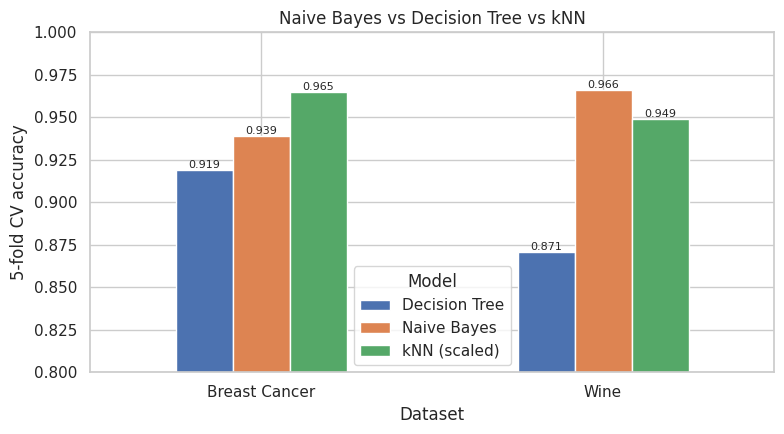

In [3]:
pivot = step1.pivot(index="Dataset", columns="Model", values="5-fold CV mean")
ax = pivot.plot(kind="bar", figsize=(8, 4.5), rot=0)
ax.set_ylabel("5-fold CV accuracy")
ax.set_ylim(0.8, 1.0)
ax.set_title("Naive Bayes vs Decision Tree vs kNN")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

**What we see:** Naive Bayes is best on Wine and scaled kNN is best on Breast Cancer. The CV mean is the more trustworthy number (the Decision Tree on Wine looks much better on one split than in CV).

## Step 2: ColumnTransformer for Titanic
- Numeric columns (`age`, `fare`, `pclass`): imputer (median) + scaler
- Categorical columns (`sex`, `embarked`): imputer (most frequent) + one-hot encoder

`sparse_output=False` makes the one-hot output a normal array, because `GaussianNB` cannot read sparse data.

In [4]:
df = sns.load_dataset("titanic")
X = df[["age", "fare", "pclass", "sex", "embarked"]]
y = df["survived"]

numeric_cols = ["age", "fare", "pclass"]
categorical_cols = ["sex", "embarked"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_cols),
    ]
)

X.isnull().sum()

age         177
fare          0
pclass        0
sex           0
embarked      2
dtype: int64

## Step 3: Wrap it with a classifier in one Pipeline
To swap the model, change **only** the `classifier = ...` line. Then `cross_val_score` is run on the **whole pipeline with raw data** (not on pre-transformed data).

In [5]:
classifier = GaussianNB()          # <- change only this line to swap the model

pipe = Pipeline([
    ("preprocess", preprocessor),
    ("clf", classifier),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

In [6]:
scores = cross_val_score(pipe, X, y, cv=5)
print("Naive Bayes pipeline 5-fold CV:", [round(float(s), 3) for s in scores])
print("Mean:", round(scores.mean(), 3))

Naive Bayes pipeline 5-fold CV: [0.76, 0.792, 0.775, 0.764, 0.792]
Mean: 0.777


**Raw data in, prediction out.** A new passenger (with the raw values, no manual preprocessing) goes straight into the fitted pipeline.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
pipe.fit(X_train, y_train)

new_passenger = pd.DataFrame(
    [{"age": 28, "fare": 70.0, "pclass": 1, "sex": "female", "embarked": "C"}]
)
print("Prediction (1 = survived):", int(pipe.predict(new_passenger)[0]))
print("Probabilities [died, survived]:", pipe.predict_proba(new_passenger).round(3))

Prediction (1 = survived): 1
Probabilities [died, survived]: [[0. 1.]]


## Step 4: Swap the classifier in the same pipeline and note the three scores

In [8]:
candidates = {
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=5),
}

results = []
for name, clf in candidates.items():
    p = Pipeline([("preprocess", preprocessor), ("clf", clf)])
    s = cross_val_score(p, X, y, cv=5)
    results.append({"Model": name, "CV mean": round(s.mean(), 3), "CV std": round(s.std(), 3)})

titanic_results = pd.DataFrame(results)
titanic_results

,Model,CV mean,CV std
0,Naive Bayes,0.777,0.014
1,Decision Tree,0.790,0.042
2,kNN,0.804,0.012


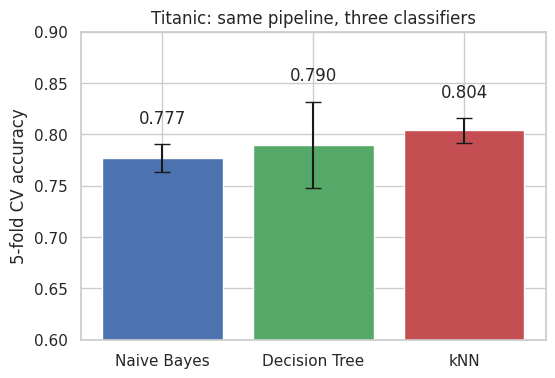

In [9]:
plt.figure(figsize=(6, 4))
bars = plt.bar(titanic_results["Model"], titanic_results["CV mean"],
               yerr=titanic_results["CV std"], capsize=6,
               color=["#4c72b0", "#55a868", "#c44e52"])
plt.bar_label(bars, fmt="%.3f", padding=12)
plt.ylim(0.6, 0.9)
plt.ylabel("5-fold CV accuracy")
plt.title("Titanic: same pipeline, three classifiers")
plt.show()

**Reading the graph:** the three scores are close. The error bars are the standard deviation across folds, and the Decision Tree has the largest one, so its score is the least stable.

---
## Notes (Wednesday)
- **What "naive" means:** Naive Bayes assumes every feature is independent of the others given the class. It is rarely true, but the model is still fast and accurate.
- **What a pipeline is:** preprocessing steps and a model chained into one object, so raw data goes in and predictions come out.
- **Why a pipeline prevents leakage:** during cross-validation it refits the imputer, scaler and encoder on each training fold only, so nothing from the test fold influences preprocessing.
- **Swapping a model:** change one line (`classifier = ...`), because the preprocessing and the rest of the pipeline stay the same.

## My results
Wine and Breast Cancer (5-fold CV mean):

| Dataset | Naive Bayes | Decision Tree | kNN (scaled) |
|---|---|---|---|
| Wine | 0.966 | 0.871 | 0.949 |
| Breast Cancer | 0.939 | 0.919 | 0.965 |

Titanic, same pipeline (5-fold CV mean): Naive Bayes 0.777, Decision Tree 0.790, kNN 0.805.